# 03 Hierarchical model in PyMC

Same target, split and test balls as `02_baseline`. The model:

$$\text{logit}\, p = \alpha_{\text{phase}} + \beta_{\text{batter}} + \gamma_{\text{bowler}}
\;[+\; \delta_{\text{venue}}]$$

with partially pooled player effects, $\beta_b = \sigma_\beta z_b$, $z_b \sim N(0, 1)$
(non-centred), and the same for bowlers. The pooling scales $\sigma_\beta, \sigma_\gamma$
are learnt from the data, so a batter with 20 balls is pulled towards the average and a
batter with 2,000 balls is not. A player first seen in the test seasons gets a fresh
effect drawn from $N(0, \sigma)$, which widens his predictions honestly.

Venue is included only if cross-validation chose it for the baseline.

**Speed.** A Bernoulli likelihood over 235,000 balls is slow for NUTS. Because the linear
predictor depends only on (batter, bowler, phase[, venue]), the Bernoulli likelihood
equals a binomial likelihood on counts per cell, up to a constant that does not involve
the parameters. So I aggregate to cells. This is exact, not an approximation;
`tests/test_hierarchical.py` checks it numerically.

In [1]:
import json
import time
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy.special import expit, logit
from sklearn.metrics import brier_score_loss, log_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RESULTS, MODELS = ROOT / "figures", ROOT / "results", ROOT / "models"
MODELS.mkdir(exist_ok=True)
SEED = 20261112
rng = np.random.default_rng(SEED)

balls = pd.read_parquet(ROOT / "data" / "legal_balls.parquet")
base = pd.read_parquet(ROOT / "data" / "test_preds_baseline.parquet")
settings = json.load(open(RESULTS / "baseline_settings.json"))
TEST_SEASONS = settings["test_seasons"]
USE_VENUE = "venue_clean" in settings["features"]
print("venue in model:", USE_VENUE, "| baseline features:", settings["features"], "C =", settings["C"])

train = balls[~balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
test = balls[balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
assert (test.wicket.to_numpy() == base.wicket.to_numpy()).all(), "test balls must match 02"

venue in model: False | baseline features: ['batter_id', 'bowler_id', 'phase'] C = 0.03


## Index players and aggregate to cells

In [2]:
PHASES = ["powerplay", "middle", "death"]
batters = pd.Index(train.batter_id.unique())
bowlers = pd.Index(train.bowler_id.unique())
venues = pd.Index(train.venue_clean.unique())
keys = ["batter_id", "bowler_id", "phase"] + (["venue_clean"] if USE_VENUE else [])

cells = train.groupby(keys, observed=True).wicket.agg(n="size", k="sum").reset_index()
cells["bat_idx"] = batters.get_indexer(cells.batter_id)
cells["bowl_idx"] = bowlers.get_indexer(cells.bowler_id)
cells["phase_idx"] = pd.Index(PHASES).get_indexer(cells.phase)
if USE_VENUE:
    cells["venue_idx"] = venues.get_indexer(cells.venue_clean)
print(f"{len(train):,} training balls -> {len(cells):,} cells; "
      f"{len(batters)} batters, {len(bowlers)} bowlers")

234,995 training balls -> 37,970 cells; 637 batters, 503 bowlers


In [3]:
def build_model(cells, prior_only=False):
    coords = {"phase": PHASES, "batter": batters, "bowler": bowlers}
    if USE_VENUE:
        coords["venue"] = venues
    with pm.Model(coords=coords) as model:
        alpha = pm.Normal("alpha", mu=logit(0.05), sigma=0.5, dims="phase")
        sigma_bat = pm.HalfNormal("sigma_bat", 0.5)
        sigma_bowl = pm.HalfNormal("sigma_bowl", 0.5)
        z_bat = pm.Normal("z_bat", 0, 1, dims="batter")
        z_bowl = pm.Normal("z_bowl", 0, 1, dims="bowler")
        bat = pm.Deterministic("bat", sigma_bat * z_bat, dims="batter")
        bowl = pm.Deterministic("bowl", sigma_bowl * z_bowl, dims="bowler")
        eta = (alpha[cells.phase_idx.to_numpy()] + bat[cells.bat_idx.to_numpy()]
               + bowl[cells.bowl_idx.to_numpy()])
        if USE_VENUE:
            sigma_venue = pm.HalfNormal("sigma_venue", 0.3)
            z_venue = pm.Normal("z_venue", 0, 1, dims="venue")
            venue = pm.Deterministic("venue", sigma_venue * z_venue, dims="venue")
            eta = eta + venue[cells.venue_idx.to_numpy()]
        pm.Binomial("k", n=cells.n.to_numpy(), logit_p=eta,
                    observed=None if prior_only else cells.k.to_numpy())
    return model

## Prior predictive check

Before fitting: do the priors allow sensible wicket rates? A T20 bowler takes a wicket
on roughly 2% to 10% of legal balls. Priors that put real mass on 40% would be careless;
priors that pin every player to 5% would leave nothing to learn.

Sampling: [alpha, k, sigma_bat, sigma_bowl, z_bat, z_bowl]


prior overall wicket rate, 5/50/95%: [0.0377 0.0644 0.1109]
prior per-batter rate v average bowler (middle overs), 5/50/95%: [0.0166 0.0501 0.1416]


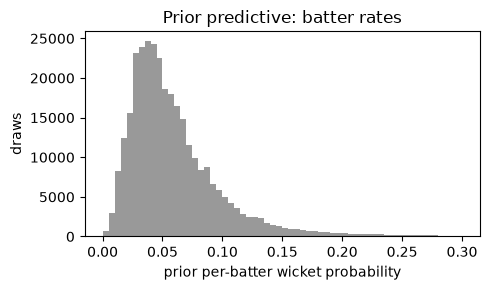

In [4]:
with build_model(cells):
    prior = pm.sample_prior_predictive(draws=500, random_seed=SEED)
pr = prior.prior
p_bat = expit(pr.alpha.sel(phase="middle") + pr.bat)  # a batter v an average bowler
p_overall = prior.prior_predictive.k.sum("k_dim_0") / cells.n.sum()
print("prior overall wicket rate, 5/50/95%:",
      np.round(np.quantile(p_overall, [0.05, 0.5, 0.95]), 4))
print("prior per-batter rate v average bowler (middle overs), 5/50/95%:",
      np.round(np.quantile(p_bat, [0.05, 0.5, 0.95]), 4))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(np.asarray(p_bat).ravel(), bins=60, range=(0, 0.3), color="#999")
ax.set(xlabel="prior per-batter wicket probability", ylabel="draws",
       title="Prior predictive: batter rates")
fig.tight_layout()

## Fit

NUTS, 4 chains, 1,000 tuning and 1,000 kept draws each, `target_accept=0.9`. The
settings and the seed are saved with the results.

In [5]:
SAMPLER = dict(draws=1000, tune=1000, chains=4, cores=4, target_accept=0.9, random_seed=SEED)
model = build_model(cells)
t0 = time.time()
with model:
    idata = pm.sample(**SAMPLER, progressbar=False)
fit_seconds = time.time() - t0
print(f"sampling took {fit_seconds / 60:.1f} minutes")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 176 seconds.


sampling took 3.0 minutes


## Sampler diagnostics

In [6]:
var_names = ["alpha", "sigma_bat", "sigma_bowl"] + (["sigma_venue"] if USE_VENUE else [])
summ_all = az.summary(idata, var_names=var_names + ["z_bat", "z_bowl"], round_to=None)
diag = {
    "divergences": int(idata.sample_stats.diverging.sum()),
    "max_rhat": float(summ_all.r_hat.max()),
    "min_ess_bulk": float(summ_all.ess_bulk.min()),
    "min_ess_tail": float(summ_all.ess_tail.min()),
    "sampling_minutes": round(fit_seconds / 60, 2),
}
print(diag)
az.summary(idata, var_names=var_names, round_to=4)

{'divergences': 0, 'max_rhat': 1.01, 'min_ess_bulk': 779.0, 'min_ess_tail': 764.0, 'sampling_minutes': 3.0}


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[powerplay],-3.1869,0.0259,-3.2370,-3.1390,0.0006,0.0004,1697.8489,2643.0738,1.0010
alpha[middle],-3.0854,0.0237,-3.1272,-3.0394,0.0006,0.0004,1496.1205,2388.0633,1.0010
alpha[death],-2.4477,0.0227,-2.4881,-2.4049,0.0006,0.0003,1639.1625,2078.0952,1.0026
sigma_bat,0.2188,0.0170,0.1889,0.2518,0.0005,0.0003,1206.1792,1968.8309,1.0034
sigma_bowl,0.0683,0.0186,0.0324,0.1020,0.0007,0.0005,779.4090,764.2969,1.0034


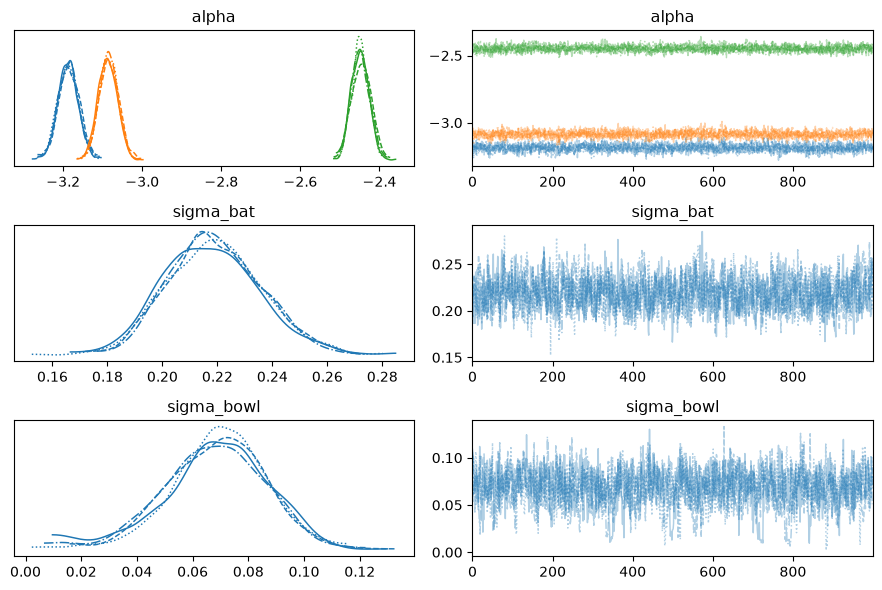

In [7]:
axes = az.plot_trace(idata, var_names=var_names, compact=True, figsize=(9, 2 * len(var_names)))
plt.tight_layout()

## Posterior predictive check on the training seasons

Does data simulated from the fitted model look like the real data? I compare the total
wickets in each phase and the spread of wicket counts per batter.

Sampling: [k]


observed sd of batter rates sits at posterior predictive quantile 0.05


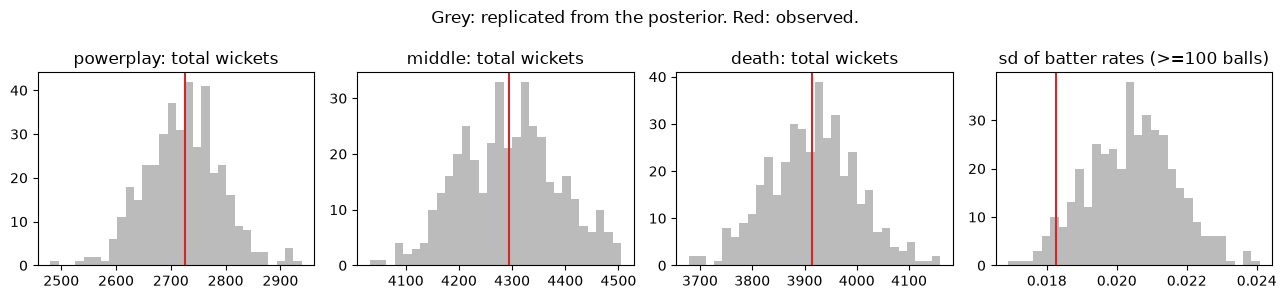

In [8]:
# every 10th draw (400 in all) keeps memory modest: cells x draws integers
thinned = idata.posterior.sel(draw=slice(None, None, 10))
with model:
    ppc = pm.sample_posterior_predictive(thinned, random_seed=SEED, progressbar=False)
k_rep = ppc.posterior_predictive.k.stack(s=("chain", "draw")).to_numpy()  # cells x draws

fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, ph in zip(ax[:3], PHASES):
    m = (cells.phase == ph).to_numpy()
    a.hist(k_rep[m].sum(0), bins=30, color="#bbb")
    a.axvline(cells.k[m].sum(), color="C3")
    a.set_title(f"{ph}: total wickets")
# standard deviation across batters of their wicket rates (players with >= 100 balls)
bat_cells = cells.groupby("bat_idx").n.transform("sum") >= 100
g = cells[bat_cells].groupby("bat_idx")
n_b = g.n.sum().to_numpy()
idx = cells[bat_cells].bat_idx.to_numpy()
codes = np.unique(idx, return_inverse=True)[1]  # sorted, same order as g.n.sum()
rep_rates = np.stack([np.bincount(codes, weights=k_rep[bat_cells.to_numpy(), j])
                      for j in range(k_rep.shape[1])]) / n_b
obs_sd = (g.k.sum().to_numpy() / n_b).std()
ax[3].hist(rep_rates.std(1), bins=30, color="#bbb")
ax[3].axvline(obs_sd, color="C3")
ax[3].set_title("sd of batter rates (>=100 balls)")
fig.suptitle("Grey: replicated from the posterior. Red: observed.")
fig.tight_layout()
fig.savefig(FIG / "ppc_train.png", dpi=120)
ppc_sd_quantile = float((rep_rates.std(1) < obs_sd).mean())
print("observed sd of batter rates sits at posterior predictive quantile", round(ppc_sd_quantile, 3))

## Predictions for the test seasons

For each test ball, the predictive probability averages $p$ over posterior draws. A
player unseen in training gets, in each draw, a new effect drawn from
$N(0, \sigma)$ for that draw.

In [9]:
post = idata.posterior.stack(s=("chain", "draw"))
S = post.sizes["s"]
alpha_s = post.alpha.transpose("phase", "s").to_numpy()        # 3 x S
bat_s = post.bat.transpose("batter", "s").to_numpy()            # B x S
bowl_s = post.bowl.transpose("bowler", "s").to_numpy()
sig_bat, sig_bowl = post.sigma_bat.to_numpy(), post.sigma_bowl.to_numpy()

new_bat = test.batter_id[~test.batter_id.isin(batters)].unique()
new_bowl = test.bowler_id[~test.bowler_id.isin(bowlers)].unique()
bat_all = np.vstack([bat_s, rng.standard_normal((len(new_bat), S)) * sig_bat])
bowl_all = np.vstack([bowl_s, rng.standard_normal((len(new_bowl), S)) * sig_bowl])
bat_index = batters.append(pd.Index(new_bat))
bowl_index = bowlers.append(pd.Index(new_bowl))

tcells = test.groupby(keys, observed=True).wicket.agg(n="size", k="sum").reset_index()
eta = (alpha_s[pd.Index(PHASES).get_indexer(tcells.phase)]
       + bat_all[bat_index.get_indexer(tcells.batter_id)]
       + bowl_all[bowl_index.get_indexer(tcells.bowler_id)])
if USE_VENUE:
    v_s = post.venue.transpose("venue", "s").to_numpy()
    new_v = tcells.venue_clean[~tcells.venue_clean.isin(venues)].unique()
    v_all = np.vstack([v_s, rng.standard_normal((len(new_v), S)) * post.sigma_venue.to_numpy()])
    eta = eta + v_all[venues.append(pd.Index(new_v)).get_indexer(tcells.venue_clean)]
p_draws = expit(eta)                                            # test cells x S
tcells["p_hier"] = p_draws.mean(1)

test_p = test.merge(tcells[keys + ["p_hier"]], on=keys, how="left")
base["p_hier"] = test_p.p_hier.to_numpy()
print("unseen batters:", len(new_bat), "unseen bowlers:", len(new_bowl))

unseen batters: 65 unseen bowlers: 46


## Test-season scores, with uncertainty

The differences are small, so I put a 95% interval on them with a bootstrap that
resamples whole matches (balls within a match are not independent).

In [10]:
def scores(y, p):
    return {"log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p)}


def match_bootstrap(df, cols, n_boot=1000, seed=SEED):
    """Bootstrap the mean per-ball loss of each column, resampling matches."""
    r = np.random.default_rng(seed)
    y = df.wicket.to_numpy()
    losses = {}
    for c in cols:
        p = df[c].to_numpy()
        losses[(c, "log_loss")] = -(y * np.log(p) + (1 - y) * np.log(1 - p))
        losses[(c, "brier")] = (p - y) ** 2
    L = pd.DataFrame(losses)
    match = df.match_id.to_numpy()
    per_match_sum = L.groupby(match).sum()
    per_match_n = L.groupby(match).size().to_numpy()
    ids = np.arange(len(per_match_sum))
    out = []
    for _ in range(n_boot):
        pick = r.choice(ids, size=len(ids), replace=True)
        out.append(per_match_sum.to_numpy()[pick].sum(0) / per_match_n[pick].sum())
    return pd.DataFrame(out, columns=per_match_sum.columns)


cols = ["p_overall", "p_logistic", "p_hier"]
names = {"p_overall": "overall rate", "p_logistic": "logistic L2", "p_hier": "hierarchical"}
results = pd.DataFrame({names[c]: scores(base.wicket, base[c]) for c in cols}).T
results["mean predicted"] = [base[c].mean() for c in cols]
results["observed rate"] = base.wicket.mean()

boot = match_bootstrap(base, cols)
diff = pd.DataFrame({
    m: boot[("p_hier", m)] - boot[("p_logistic", m)] for m in ["log_loss", "brier"]
})
diff_ci = diff.quantile([0.025, 0.5, 0.975]).T
diff_ci.columns = ["2.5%", "median", "97.5%"]
print("hierarchical minus logistic (negative favours hierarchical):")
print(diff_ci.to_string(float_format=lambda x: f"{x:.6f}"))
results.round(5)

hierarchical minus logistic (negative favours hierarchical):
              2.5%    median     97.5%
log_loss -0.000265 -0.000131 -0.000008
brier    -0.000026 -0.000011  0.000002


,log_loss,brier,mean predicted,observed rate
overall rate,0.19973,0.04784,0.04653,0.05036
logistic L2,0.19726,0.04759,0.04854,0.05036
hierarchical,0.19713,0.04758,0.04847,0.05036


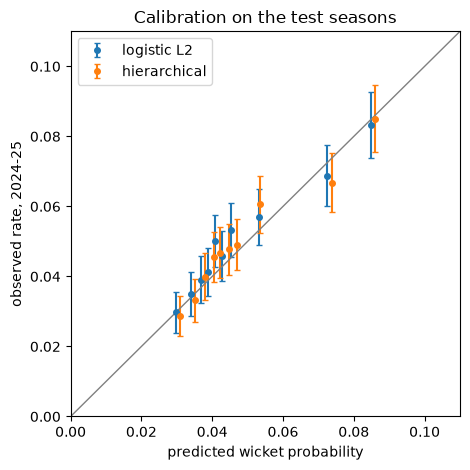

In [11]:
def calibration_points(y, p, n_bins=10):
    q = pd.qcut(p, n_bins, duplicates="drop")
    g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True)
    obs, n = g.y.mean(), g.y.size()
    return g.p.mean(), obs, 1.96 * np.sqrt(obs * (1 - obs) / n)


fig, ax = plt.subplots(figsize=(4.8, 4.8))
for c, off in [("p_logistic", -0.0007), ("p_hier", 0.0007)]:
    x, yv, e = calibration_points(base.wicket, base[c])
    ax.errorbar(x + off, yv, yerr=e, fmt="o", ms=4, capsize=2, label=names[c])
lim = [0, 0.11]
ax.plot(lim, lim, color="grey", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="predicted wicket probability",
       ylabel="observed rate, 2024-25", title="Calibration on the test seasons")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "calibration_test.png", dpi=120)

## Where does partial pooling matter? Players with few balls

Split the test balls by how many training balls the batter (and, separately, the
bowler) had, and compare the two models within each group.

In [12]:
bat_n = train.batter_id.value_counts()
bowl_n = train.bowler_id.value_counts()
bands = [-1, 0, 99, 499, np.inf]
labels = ["unseen", "1-99", "100-499", "500+"]
base["bat_band"] = pd.cut(base.batter_id.map(bat_n).fillna(0), bands, labels=labels)
base["bowl_band"] = pd.cut(base.bowler_id.map(bowl_n).fillna(0), bands, labels=labels)

rows = []
for who, col in [("batter", "bat_band"), ("bowler", "bowl_band")]:
    for lab in labels:
        sub = base[base[col] == lab]
        b = match_bootstrap(sub, ["p_logistic", "p_hier"], n_boot=500)
        dd = b[("p_hier", "log_loss")] - b[("p_logistic", "log_loss")]
        rows.append({
            "player": who, "training balls": lab, "test balls": len(sub),
            "log loss logistic": log_loss(sub.wicket, sub.p_logistic, labels=[0, 1]),
            "log loss hierarchical": log_loss(sub.wicket, sub.p_hier, labels=[0, 1]),
            "difference": dd.median(), "diff 2.5%": dd.quantile(0.025),
            "diff 97.5%": dd.quantile(0.975),
        })
by_band = pd.DataFrame(rows)
by_band.round(5)

,player,training balls,test balls,log loss logistic,log loss hierarchical,difference,diff 2.5%,diff 97.5%
0,batter,unseen,4160,0.23351,0.23319,-0.00032,-0.00067,-0.00001
1,batter,1-99,2741,0.22252,0.22245,-0.00012,-0.00078,0.00051
2,batter,100-499,8639,0.19839,0.19825,-0.00014,-0.00040,0.00013
3,batter,500+,17266,0.18396,0.18387,-0.00010,-0.00027,0.00007
4,bowler,unseen,3685,0.18706,0.18712,0.00006,-0.00018,0.00030
5,bowler,1-99,1646,0.19642,0.19649,0.00007,-0.00038,0.00050
6,bowler,100-499,8033,0.19502,0.19480,-0.00022,-0.00046,-0.00001
7,bowler,500+,19442,0.20019,0.20005,-0.00016,-0.00034,0.00003


## Estimates for thin and thick players

Put both models on the same scale: each batter's wicket probability against an average
bowler in the middle overs (venue at its average). For the logistic model that is the
intercept plus the middle-overs and batter coefficients; for the hierarchical model it
is the posterior distribution of the same quantity.

raw_rate         logistic         hier_mean        
             std     max      std     max       std     max
band                                                       
1-99      0.1501  1.0000   0.0013  0.0490    0.0027  0.0570
100-499   0.0194  0.1193   0.0028  0.0521    0.0044  0.0581
500+      0.0115  0.1055   0.0065  0.0755    0.0069  0.0789

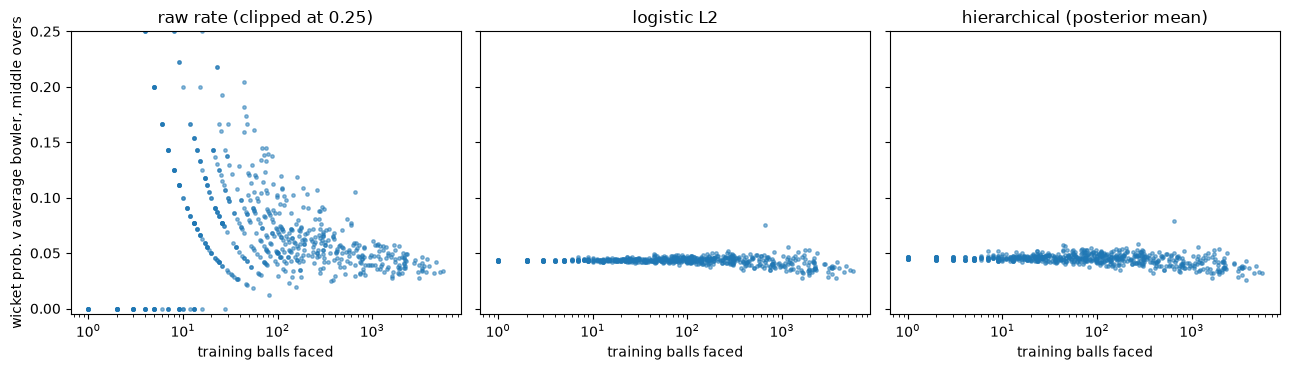

In [13]:
# refit the chosen logistic to read its coefficients
from sklearn.compose import ColumnTransformer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.pipeline import make_pipeline  # noqa: E402
from sklearn.preprocessing import OneHotEncoder  # noqa: E402

feats = settings["features"]
enc = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), feats)])
logit_model = make_pipeline(enc, LogisticRegression(C=settings["C"], max_iter=2000))
logit_model.fit(train[feats], train.wicket)
oh = logit_model[0].named_transformers_["onehot"]
coef = pd.Series(logit_model[-1].coef_[0], index=oh.get_feature_names_out(feats))
icpt = logit_model[-1].intercept_[0]
venue_mean = coef[coef.index.str.startswith("venue_clean_")].mean() if USE_VENUE else 0.0
lr_bat = expit(icpt + coef["phase_middle"] + venue_mean
               + coef[[f"batter_id_{b}" for b in batters]].to_numpy())

hb = expit(alpha_s[1][None, :] + bat_s)                          # batters x S, middle overs
est = pd.DataFrame({
    "batter_id": batters, "train_balls": bat_n.reindex(batters).to_numpy(),
    "train_wickets": train.groupby("batter_id").wicket.sum().reindex(batters).to_numpy(),
    "logistic": lr_bat, "hier_mean": hb.mean(1),
    "hier_10": np.quantile(hb, 0.1, axis=1), "hier_90": np.quantile(hb, 0.9, axis=1),
})
est["raw_rate"] = est.train_wickets / est.train_balls
est["name"] = est.batter_id.map(train.drop_duplicates("batter_id").set_index("batter_id").batter)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, col, title in [(ax[0], "raw_rate", "raw rate"), (ax[1], "logistic", "logistic L2"),
                      (ax[2], "hier_mean", "hierarchical (posterior mean)")]:
    a.scatter(est.train_balls, est[col], s=6, alpha=0.5)
    a.set_xscale("log")
    a.set_title(title)
    a.set_xlabel("training balls faced")
ax[0].set_ylabel("wicket prob. v average bowler, middle overs")
ax[0].set_ylim(-0.005, 0.25)
ax[0].set_title("raw rate (clipped at 0.25)")
fig.tight_layout()
fig.savefig(FIG / "shrinkage_batters.png", dpi=120)

est["band"] = pd.cut(est.train_balls, [0, 99, 499, np.inf], labels=["1-99", "100-499", "500+"])
est.groupby("band", observed=True)[["raw_rate", "logistic", "hier_mean"]].agg(["std", "max"]).round(4)

### Credible intervals for a handful of batters

Three batters with long careers and three with very few balls. The 80% interval is the
central 80% of the posterior for the batter's wicket probability against an average
bowler in the middle overs.

In [14]:
thick = est.nlargest(3, "train_balls")
thin = est[(est.train_balls >= 15) & (est.train_balls <= 40)].sample(3, random_state=SEED)
show = pd.concat([thick, thin])[["name", "train_balls", "train_wickets", "raw_rate", "logistic",
                                 "hier_mean", "hier_10", "hier_90"]]
show.round(4)

,name,train_balls,train_wickets,raw_rate,logistic,hier_mean,hier_10,hier_90
7,V Kohli,5568,186,0.0334,0.0339,0.0320,0.0292,0.0349
41,S Dhawan,5181,170,0.0328,0.0343,0.0332,0.0302,0.0362
56,RG Sharma,4759,198,0.0416,0.0380,0.0379,0.0348,0.0411
143,LPC Silva,26,2,0.0769,0.0436,0.0456,0.0340,0.0580
156,T Thushara,18,1,0.0556,0.0428,0.0439,0.0329,0.0560
440,Basil Thampi,35,1,0.0286,0.0418,0.0415,0.0317,0.0526


## Are the intervals calibrated on the test seasons?

For each batter and each bowler with at least 60 legal balls in 2024-25, take the
posterior predictive distribution of their **total bowler wickets in the test seasons**,
given the balls they actually faced or bowled (opponents and phases included). Then ask
how often the observed total falls inside the central 50%, 80% and 95% intervals.

The logistic model has no posterior, so its natural interval is a plug-in one: binomial
noise around its point predictions, ignoring parameter uncertainty. Counts are whole
numbers, so an interval with inclusive ends tends to cover a little more than its
nominal level; I also report a randomised PIT version that corrects for this.

In [15]:
def coverage_table(min_balls=60, levels=(0.5, 0.8, 0.95), n_draws=2000):
    r = np.random.default_rng(SEED)
    pick = r.choice(S, size=min(n_draws, S), replace=False)
    # simulate wicket counts per test cell, per draw: hierarchical uses the posterior draw
    # of p; plug-in logistic uses its point prediction in every draw
    tc = tcells.copy()
    lr_cell = (test.assign(p=base.p_logistic.to_numpy())
               .groupby(keys, observed=True).p.mean().reset_index())
    tc = tc.merge(lr_cell, on=keys, how="left")
    sims = {
        "hierarchical": r.binomial(tc.n.to_numpy()[:, None], p_draws[:, pick]),
        "logistic plug-in": r.binomial(tc.n.to_numpy()[:, None], tc.p.to_numpy()[:, None],
                                       size=(len(tc), len(pick))),
    }
    rows = []
    for who, col in [("batters", "batter_id"), ("bowlers", "bowler_id")]:
        nb = tc.groupby(col).n.sum()
        players = nb[nb >= min_balls].index
        codes = pd.Index(players).get_indexer(tc[col])
        m = codes >= 0
        obs = np.bincount(codes[m], weights=tc.k.to_numpy()[m], minlength=len(players))
        for model_name, sim in sims.items():
            tot = np.zeros((len(players), sim.shape[1]))
            np.add.at(tot, codes[m], sim[m])
            # randomised PIT: P(X < obs) + U * P(X = obs)
            below = (tot < obs[:, None]).mean(1)
            at = (tot == obs[:, None]).mean(1)
            pit = below + r.uniform(size=len(players)) * at
            row = {"players": who, "model": model_name, "n players": len(players)}
            for lev in levels:
                lo = np.quantile(tot, (1 - lev) / 2, axis=1)
                hi = np.quantile(tot, 1 - (1 - lev) / 2, axis=1)
                row[f"{int(lev * 100)}% interval"] = ((obs >= lo) & (obs <= hi)).mean()
                row[f"{int(lev * 100)}% PIT"] = (np.abs(pit - 0.5) <= lev / 2).mean()
            rows.append(row)
    return pd.DataFrame(rows)


coverage = coverage_table()
coverage.round(3)

,players,model,n players,50% interval,50% PIT,80% interval,80% PIT,95% interval,95% PIT
0,batters,hierarchical,109,0.587,0.440,0.853,0.817,0.963,0.954
1,batters,logistic plug-in,109,0.514,0.404,0.807,0.780,0.963,0.936
2,bowlers,hierarchical,112,0.545,0.455,0.804,0.768,0.973,0.955
3,bowlers,logistic plug-in,112,0.527,0.420,0.795,0.750,0.964,0.938


## What this shows

* **The sampler is healthy.** No divergences, R-hat at most 1.01, bulk ESS at least
  779 for every parameter. Aggregating to 37,970 cells made full NUTS take about three
  minutes, with no approximation.
* **On point prediction the two models are close to a tie.** The hierarchical model's
  test log loss is 0.19713 against 0.19726 for the logistic regression, a difference of
  -0.00013 with a 95% match-bootstrap interval of -0.00027 to -0.00001. That is a
  0.07% improvement whose interval only just excludes zero; on Brier score the
  interval includes zero. Neither model is meaningfully better at predicting the next
  ball.
* **Where it helps most is batters it has never seen.** On the 4,160 test balls faced
  by batters new in 2024-25, the hierarchical model is better by 0.00032 (interval
  -0.00067 to -0.00001), because it learns how far a new batter is likely to sit from
  average instead of assuming he is exactly average. For most other groups the
  interval includes zero.
* **Both models shrink thin players hard.** Raw rates for batters with under 100 balls
  range from 0 to 1. The L2 logistic shrinks them even more than the hierarchical model
  does (standard deviation 0.0013 against 0.0027), but with one penalty for everyone
  and no statement of how unsure it is.
* **The intervals are roughly right, and wider where they should be.** An 80% interval
  for a batter's test-season wicket total covers 85% of batters (PIT version 82%) and
  80% of bowlers (PIT 77%). With about 110 players per group, each figure has a
  standard error of about 4 percentage points, so these are consistent with 80% but
  cannot separate the hierarchical model from plug-in binomial intervals around the
  logistic predictions. A thin batter such as T Thushara (18 balls) gets an 80%
  interval of 3.3% to 5.6%; V Kohli (5,568 balls) gets 2.9% to 3.5%.
* **One misfit.** The posterior predictive check puts the observed spread of batter
  rates (batters with 100+ balls) at the 5th percentile of the replicated spread: the
  model expects batters to differ a little more than they do. A likely reason is that
  a batter's role (opener or tail-ender) changes which balls he faces, and the model
  has no term for it.
* Bowlers vary much less than batters on this target: sigma_bowl is 0.068 against 0.219
  for batters, on the log-odds scale.

## Save results

In [16]:
results.to_csv(RESULTS / "test_metrics.csv")
diff_ci.to_csv(RESULTS / "test_metric_differences.csv")
by_band.to_csv(RESULTS / "test_by_training_balls.csv", index=False)
coverage.to_csv(RESULTS / "interval_coverage.csv", index=False)
show.to_csv(RESULTS / "example_batters.csv", index=False)
with open(RESULTS / "hierarchical_run.json", "w") as f:
    json.dump({"sampler": {k: v for k, v in SAMPLER.items()}, "diagnostics": diag,
               "use_venue": USE_VENUE, "n_cells": len(cells), "n_train_balls": len(train),
               "ppc_sd_quantile": ppc_sd_quantile,
               "pymc": pm.__version__, "arviz": az.__version__}, f, indent=2)
idata.to_netcdf(MODELS / "hierarchical.nc")
print("saved results/*.csv, results/hierarchical_run.json, models/hierarchical.nc")

saved results/*.csv, results/hierarchical_run.json, models/hierarchical.nc
